# H&M Median Dataset — Visual EDA

Explore the median_version dataset visually. Look for outliers, patterns, and ways to improve the data.

Each section has a HINT telling you what to look for.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

DATA_DIR = r'A:\IDEs\PyCharm\hAnd-m-PersonalizedFashionRecommendations\clean dataset\median_version'

articles = pd.read_parquet(os.path.join(DATA_DIR, 'articles.parquet'))
customers = pd.read_parquet(os.path.join(DATA_DIR, 'customers.parquet'))
transactions = pd.read_parquet(os.path.join(DATA_DIR, 'transactions.parquet'))

print(f'articles: {articles.shape}')
print(f'customers: {customers.shape}')
print(f'transactions: {transactions.shape}')

articles: (105542, 25)
customers: (1371980, 7)
transactions: (31788324, 5)


---
## 1. Transactions Over Time

Daily purchase counts across the full date range.

**HINT — what to look for:**
- Sudden spikes or drops (Black Friday, Christmas, sales events)
- Gaps with zero purchases (data collection issues)
- Seasonal patterns (more in winter? summer?)
- Is the data growing or declining over time?
- Any weird flat-line periods (possible data issue)

C:\Users\MysticByte\AppData\Local\Temp\ipykernel_30008\4032429262.py:11: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = daily.resample('M').mean()


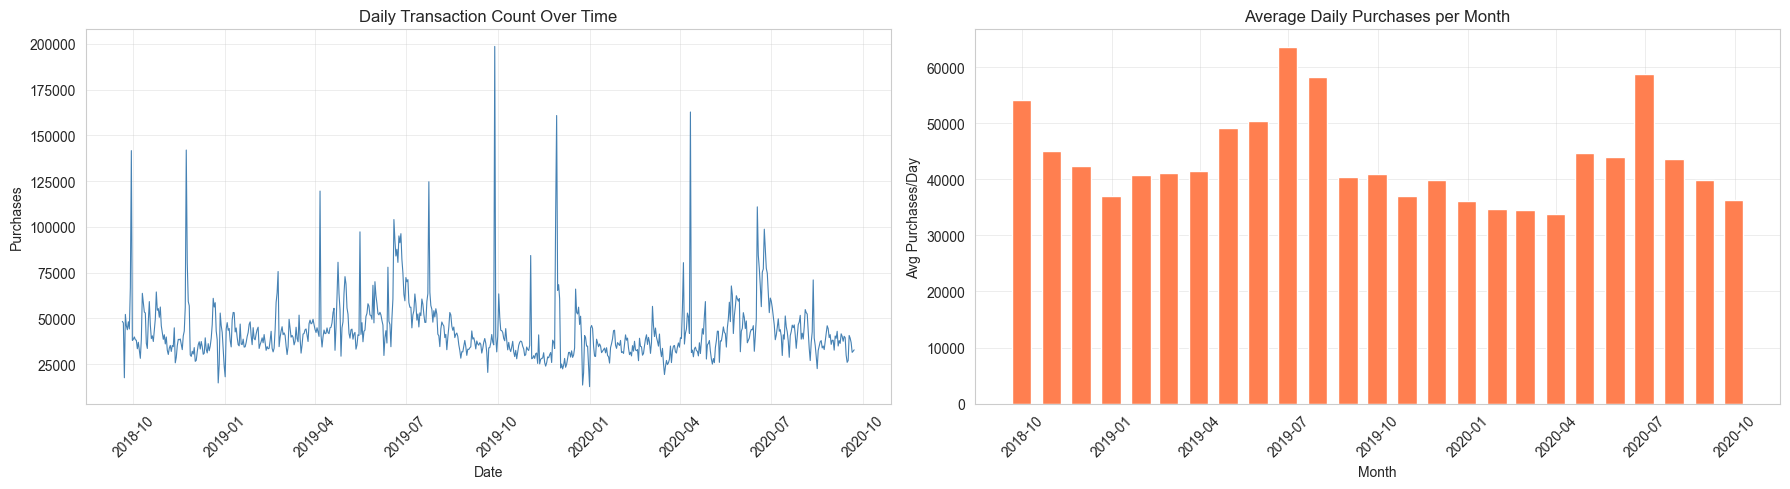

In [2]:
daily = transactions.groupby('t_dat').size()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].plot(daily.index, daily.values, color='steelblue', linewidth=0.8)
axes[0].set_title('Daily Transaction Count Over Time')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Purchases')
axes[0].tick_params(axis='x', rotation=45)

monthly = daily.resample('M').mean()
axes[1].bar(monthly.index, monthly.values, color='coral', width=20)
axes[1].set_title('Average Daily Purchases per Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Avg Purchases/Day')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 2. Price Distribution

How are prices spread across all purchases.

**HINT — what to look for:**
- Prices near 0 (almost free items — real or error?)
- Extremely high prices (outliers — luxury items or data errors?)
- Is the distribution mostly low-price (cheap clothes) or spread out?
- Where are most purchases concentrated?
- Could you create price brackets (cheap, mid, expensive) as a new feature?

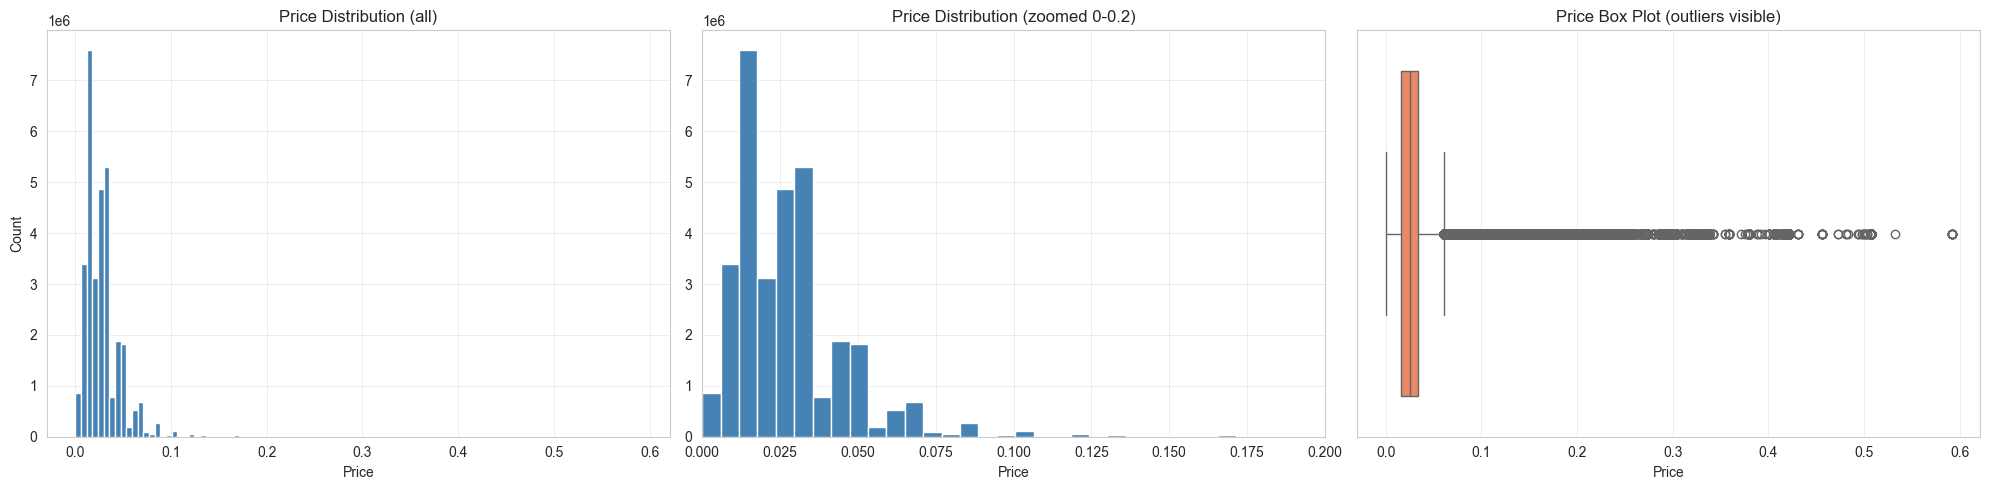

Price stats:
count    3.178832e+07
mean     2.782927e-02
std      1.918113e-02
min      1.694915e-05
25%      1.581356e-02
50%      2.540678e-02
75%      3.388136e-02
max      5.915254e-01
Name: price, dtype: float64

Prices above 0.5: 158 (0.00%)
Prices near 0 (<0.001): 14288


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].hist(transactions['price'], bins=100, color='steelblue', edgecolor='white')
axes[0].set_title('Price Distribution (all)')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')

axes[1].hist(transactions['price'], bins=100, color='steelblue', edgecolor='white')
axes[1].set_xlim(0, 0.2)
axes[1].set_title('Price Distribution (zoomed 0-0.2)')
axes[1].set_xlabel('Price')

sns.boxplot(x=transactions['price'], ax=axes[2], color='coral')
axes[2].set_title('Price Box Plot (outliers visible)')
axes[2].set_xlabel('Price')

plt.tight_layout()
plt.show()

print(f'Price stats:')
print(transactions['price'].describe())
print(f'\nPrices above 0.5: {(transactions["price"] > 0.5).sum()} ({(transactions["price"] > 0.5).sum()/len(transactions)*100:.2f}%)')
print(f'Prices near 0 (<0.001): {(transactions["price"] < 0.001).sum()}')

## 3. Customer Age Distribution

Who are the customers by age.

**HINT — what to look for:**
- Which age group buys the most?
- Any weird age values (0, negative, or 100+)?
- Is the median fill creating a fake spike at one age?
- Could you create age groups (18-25, 26-35, etc.) as a new feature?
- Any age group that's underrepresented but could be important?

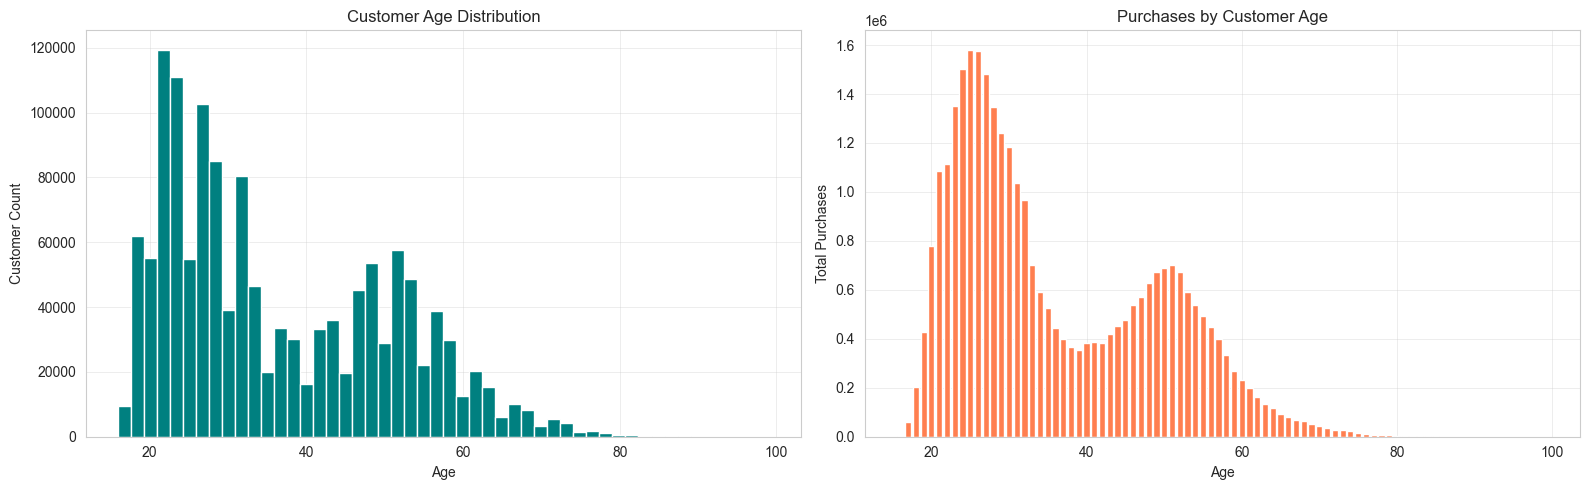

Age stats:
count    1.371980e+06
mean     3.633625e+01
std      1.423837e+01
min      1.600000e+01
25%      2.400000e+01
50%      3.200000e+01
75%      4.900000e+01
max      9.900000e+01
Name: age, dtype: float64

Median age (filled value): 32.0
Customers at median age: 44215 (could be filled NaNs)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(customers['age'].dropna(), bins=50, color='teal', edgecolor='white')
axes[0].set_title('Customer Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Customer Count')

tx_with_age = transactions.merge(customers[['customer_id', 'age']], on='customer_id', how='left')
age_purchases = tx_with_age.groupby('age').size()
axes[1].bar(age_purchases.index, age_purchases.values, color='coral')
axes[1].set_title('Purchases by Customer Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Total Purchases')

plt.tight_layout()
plt.show()

print(f'Age stats:')
print(customers['age'].describe())
print(f'\nMedian age (filled value): {customers["age"].median()}')
print(f'Customers at median age: {(customers["age"] == customers["age"].median()).sum()} (could be filled NaNs)')

## 4. Purchases Per Customer

How active is each customer? Some buy a lot, some buy once.

**HINT — what to look for:**
- Most customers buying only 1-2 items? (long tail / cold-start problem)
- A few customers buying hundreds? (power buyers — outliers?)
- The gap between 1-time buyers and repeat buyers
- Could you add a feature like "customer_activity_level" (low/medium/high)?
- Are there customers with 0 purchases? (in customers.csv but not in transactions)

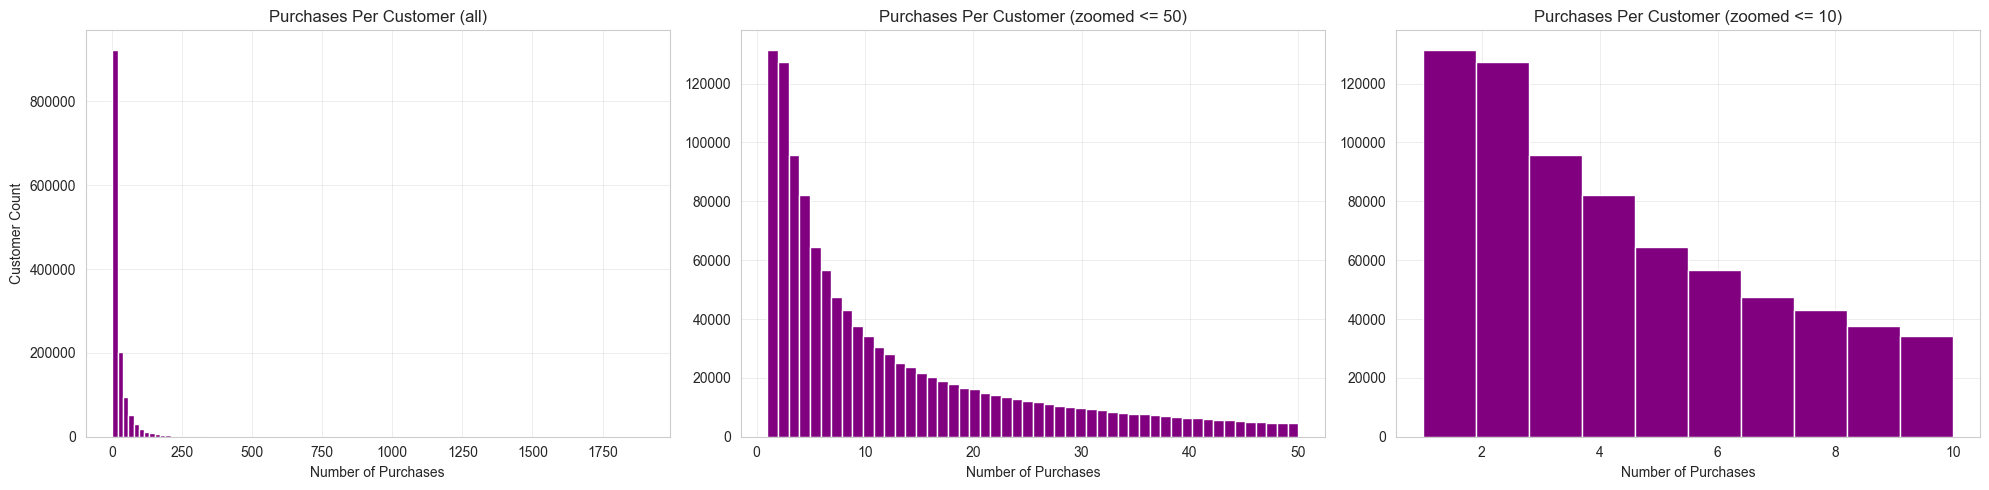

Purchases per customer stats:
count    1.362281e+06
mean     2.333463e+01
std      3.924225e+01
min      1.000000e+00
25%      3.000000e+00
50%      9.000000e+00
75%      2.700000e+01
max      1.895000e+03
dtype: float64

Customers with 1 purchase: 131514 (9.7%)
Customers with 100+ purchases: 57266
Customers with 0 purchases (in customers.csv but not transactions): 9699


In [5]:
purchases_per_cust = transactions.groupby('customer_id').size()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].hist(purchases_per_cust, bins=100, color='purple', edgecolor='white')
axes[0].set_title('Purchases Per Customer (all)')
axes[0].set_xlabel('Number of Purchases')
axes[0].set_ylabel('Customer Count')

axes[1].hist(purchases_per_cust[purchases_per_cust <= 50], bins=50, color='purple', edgecolor='white')
axes[1].set_title('Purchases Per Customer (zoomed <= 50)')
axes[1].set_xlabel('Number of Purchases')

axes[2].hist(purchases_per_cust[purchases_per_cust <= 10], bins=10, color='purple', edgecolor='white')
axes[2].set_title('Purchases Per Customer (zoomed <= 10)')
axes[2].set_xlabel('Number of Purchases')

plt.tight_layout()
plt.show()

print(f'Purchases per customer stats:')
print(purchases_per_cust.describe())
print(f'\nCustomers with 1 purchase: {(purchases_per_cust == 1).sum()} ({(purchases_per_cust == 1).sum()/len(purchases_per_cust)*100:.1f}%)')
print(f'Customers with 100+ purchases: {(purchases_per_cust >= 100).sum()}')
print(f'Customers with 0 purchases (in customers.csv but not transactions): {customers["customer_id"].nunique() - purchases_per_cust.index.nunique()}')

## 5. Purchases Per Article

Which products sell a lot and which don't sell at all.

**HINT — what to look for:**
- A few blockbuster items selling thousands of times? (popularity skew)
- Many articles with 0 or 1 purchase? (dead catalogue — item cold-start)
- The huge gap between popular and unpopular items
- Could you add a "popularity_tier" feature (top 100, mid, rare, never sold)?
- Articles never bought — should they be removed or kept for cold-start?

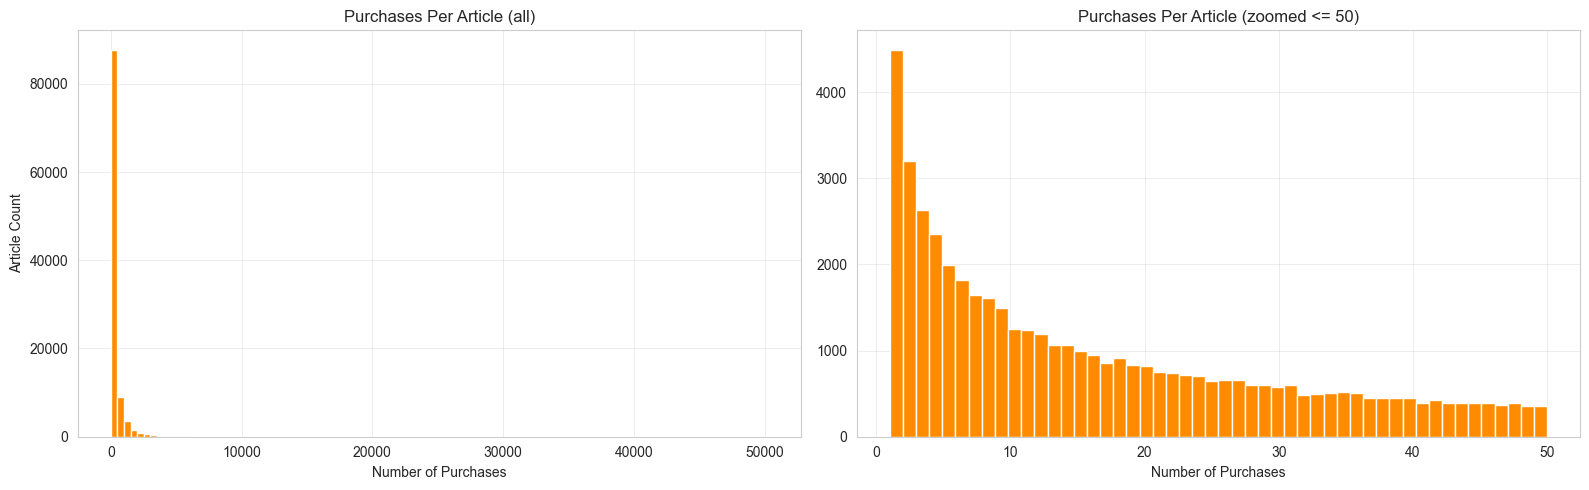

Purchases per article stats:
count    104547.000000
mean        304.057735
std         791.266060
min           1.000000
25%          14.000000
50%          65.000000
75%         286.000000
max       50287.000000
dtype: float64

Articles never bought: 995 out of 105542 (0.9%)
Articles bought only once: 4491
Top 10 most popular articles:
article_id
706016001    50287
706016002    35043
372860001    31718
610776002    30199
759871002    26329
464297007    25025
372860002    24458
610776001    22451
399223001    22236
706016003    21241
dtype: int64


In [6]:
purchases_per_art = transactions.groupby('article_id').size()
all_articles = set(articles['article_id'].unique())
bought_articles = set(purchases_per_art.index)
never_bought = all_articles - bought_articles

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(purchases_per_art, bins=100, color='darkorange', edgecolor='white')
axes[0].set_title('Purchases Per Article (all)')
axes[0].set_xlabel('Number of Purchases')
axes[0].set_ylabel('Article Count')

axes[1].hist(purchases_per_art[purchases_per_art <= 50], bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Purchases Per Article (zoomed <= 50)')
axes[1].set_xlabel('Number of Purchases')

plt.tight_layout()
plt.show()

print(f'Purchases per article stats:')
print(purchases_per_art.describe())
print(f'\nArticles never bought: {len(never_bought)} out of {len(all_articles)} ({len(never_bought)/len(all_articles)*100:.1f}%)')
print(f'Articles bought only once: {(purchases_per_art == 1).sum()}')
print(f'Top 10 most popular articles:')
print(purchases_per_art.nlargest(10))

## 6. Product Categories

Which types of products are bought most.

**HINT — what to look for:**
- Which product group dominates? (Garment? Accessories?)
- Are there tiny categories with almost no sales?
- Could rare categories be merged together?
- Which colour or department sells most?
- Any category that could be a strong feature for recommendation?

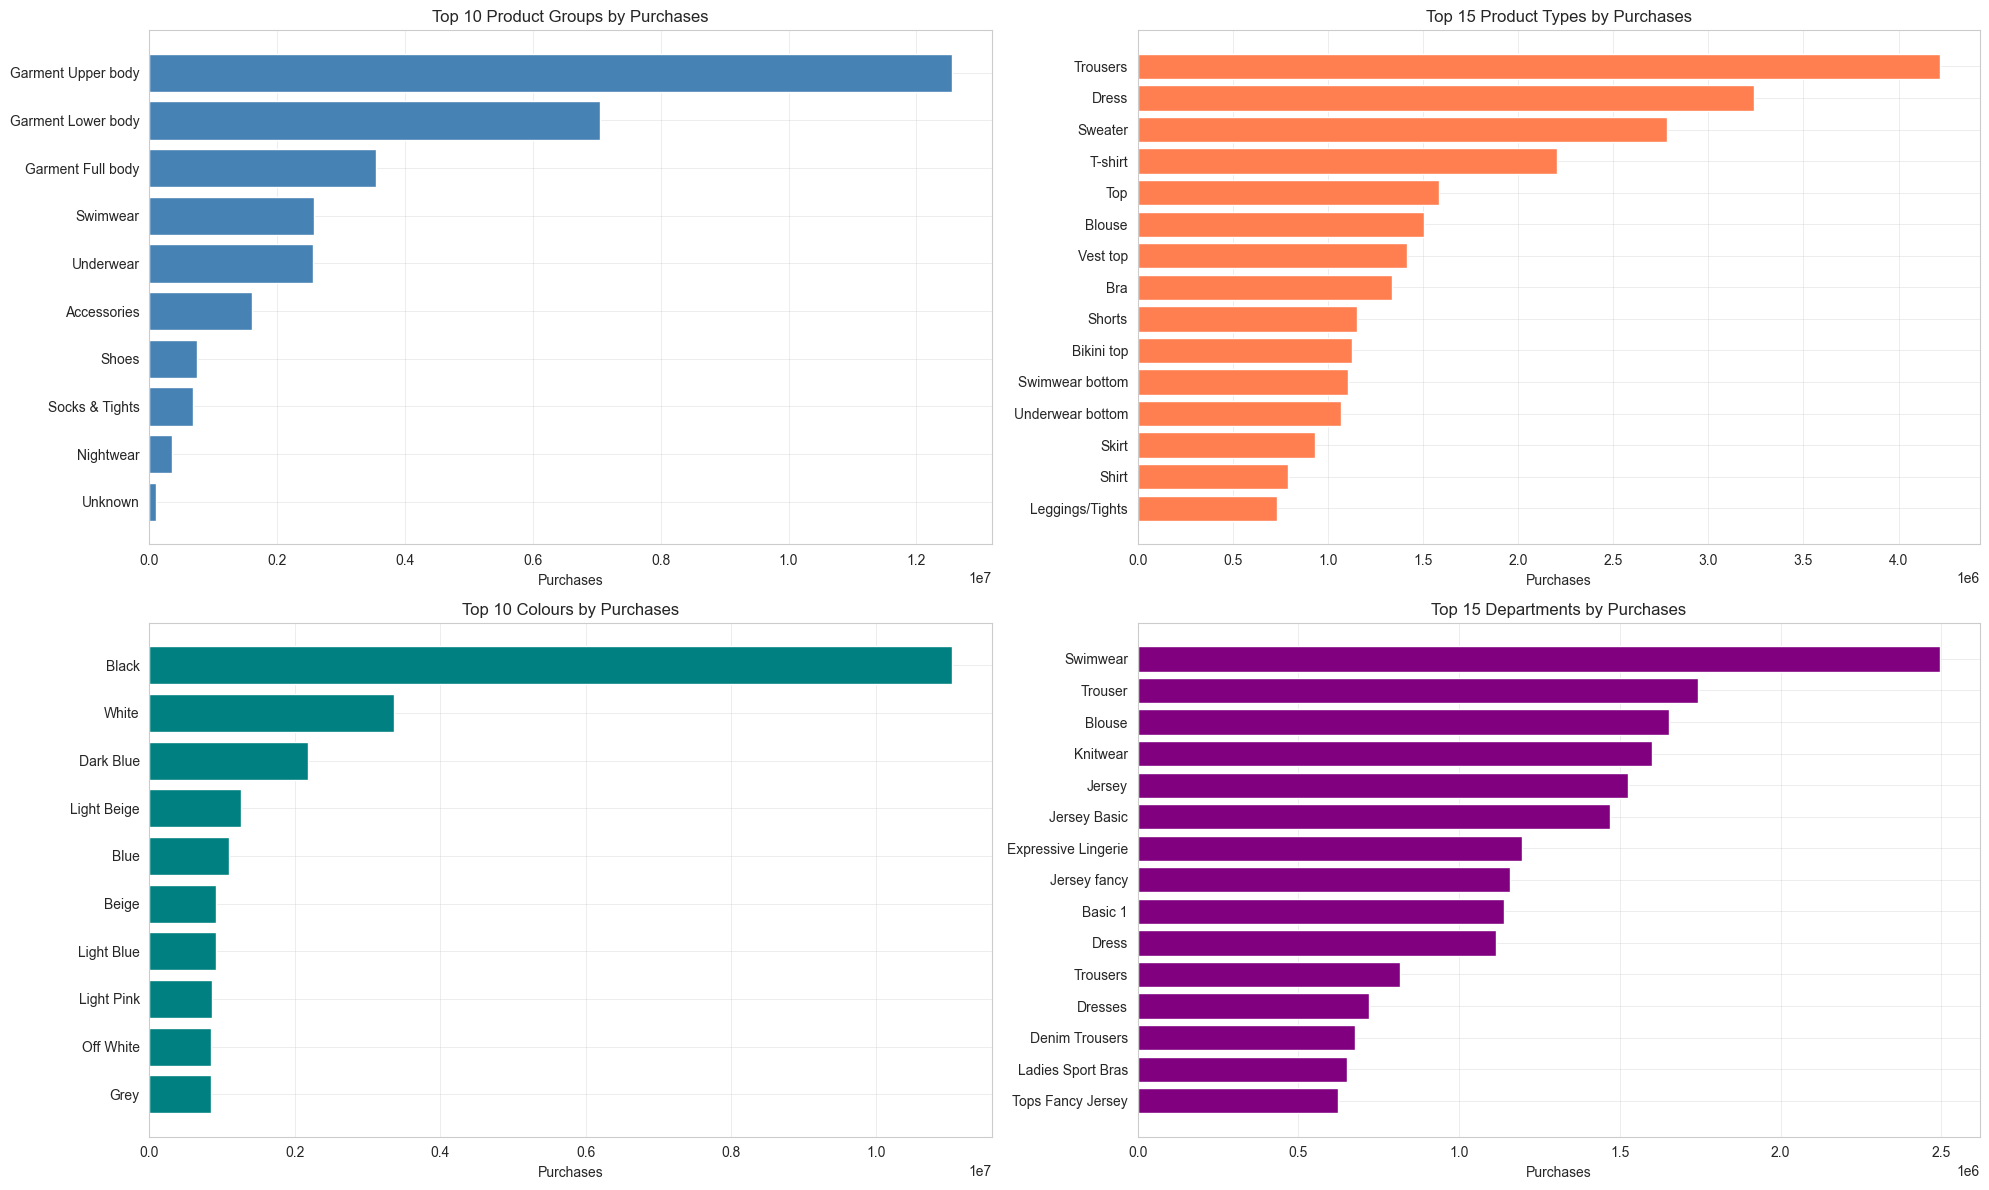

In [7]:
tx_articles = transactions.merge(articles, on='article_id', how='left')

fig, axes = plt.subplots(2, 2, figsize=(20, 12))

top_groups = tx_articles['product_group_name'].value_counts().head(10)
axes[0,0].barh(top_groups.index[::-1], top_groups.values[::-1], color='steelblue')
axes[0,0].set_title('Top 10 Product Groups by Purchases')
axes[0,0].set_xlabel('Purchases')

top_types = tx_articles['product_type_name'].value_counts().head(15)
axes[0,1].barh(top_types.index[::-1], top_types.values[::-1], color='coral')
axes[0,1].set_title('Top 15 Product Types by Purchases')
axes[0,1].set_xlabel('Purchases')

top_colors = tx_articles['colour_group_name'].value_counts().head(10)
axes[1,0].barh(top_colors.index[::-1], top_colors.values[::-1], color='teal')
axes[1,0].set_title('Top 10 Colours by Purchases')
axes[1,0].set_xlabel('Purchases')

top_depts = tx_articles['department_name'].value_counts().head(15)
axes[1,1].barh(top_depts.index[::-1], top_depts.values[::-1], color='purple')
axes[1,1].set_title('Top 15 Departments by Purchases')
axes[1,1].set_xlabel('Purchases')

plt.tight_layout()
plt.show()

## 7. Sales Channel — Online vs Store

Channel 1 = store, Channel 2 = online.

**HINT — what to look for:**
- Is online or store dominant?
- Does the channel mix change over time? (e.g., more online in recent months)
- Could channel preference be a feature? (some customers only buy online)
- Any sudden shift that could affect your time-based split?

C:\Users\MysticByte\AppData\Local\Temp\ipykernel_30008\595466617.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  channel_time = transactions.groupby([pd.Grouper(key='t_dat', freq='M'), 'sales_channel_id']).size().unstack()


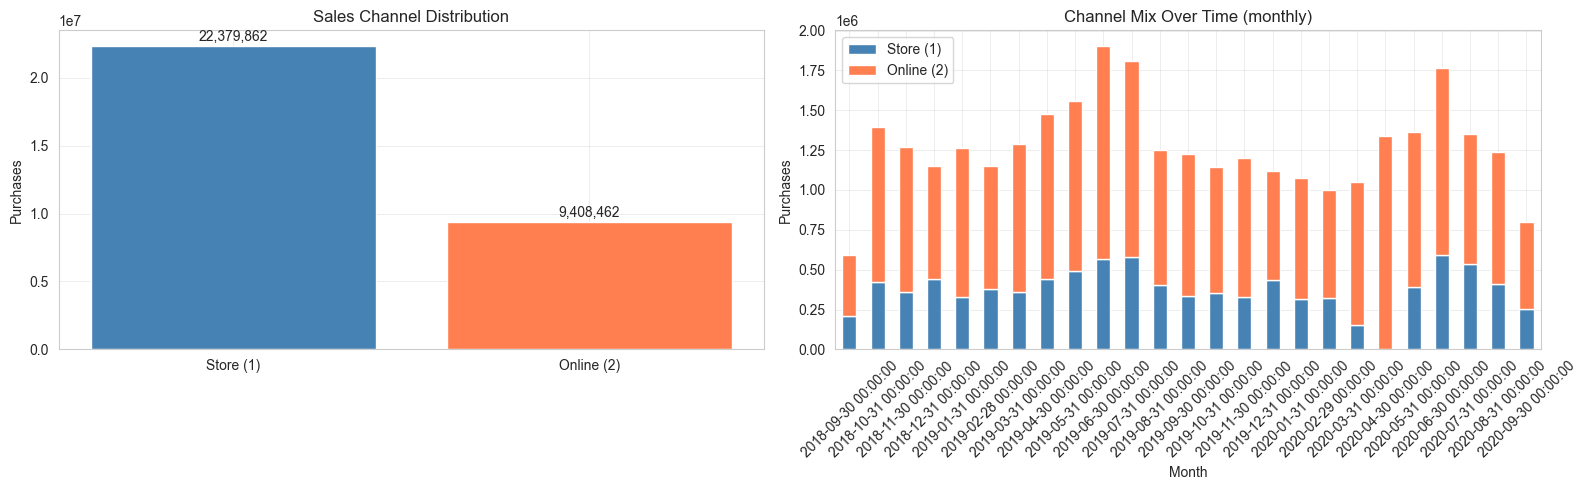

Channel split:
  Channel 2: 22,379,862 (70.4%)
  Channel 1: 9,408,462 (29.6%)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

channel_counts = transactions['sales_channel_id'].value_counts()
axes[0].bar(['Store (1)', 'Online (2)'], channel_counts.values, color=['steelblue', 'coral'])
axes[0].set_title('Sales Channel Distribution')
axes[0].set_ylabel('Purchases')
for i, v in enumerate(channel_counts.values):
    axes[0].text(i, v + len(transactions)*0.01, f'{v:,}', ha='center')

channel_time = transactions.groupby([pd.Grouper(key='t_dat', freq='M'), 'sales_channel_id']).size().unstack()
channel_time.plot(kind='bar', stacked=True, ax=axes[1], color=['steelblue', 'coral'])
axes[1].set_title('Channel Mix Over Time (monthly)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Purchases')
axes[1].legend(['Store (1)', 'Online (2)'])
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f'Channel split:')
for ch, count in channel_counts.items():
    print(f'  Channel {ch}: {count:,} ({count/len(transactions)*100:.1f}%)')

## 8. Customer Demographics

Club member status, fashion news frequency, FN, Active.

**HINT — what to look for:**
- How many customers are ACTIVE vs UNKNOWN (filled by median/mode)?
- Does the filled UNKNOWN category dominate? (could bias the model)
- Could club_member_status be a strong predictor?
- Are fashion_news customers more active buyers?
- Is FN or Active actually useful or mostly one value?

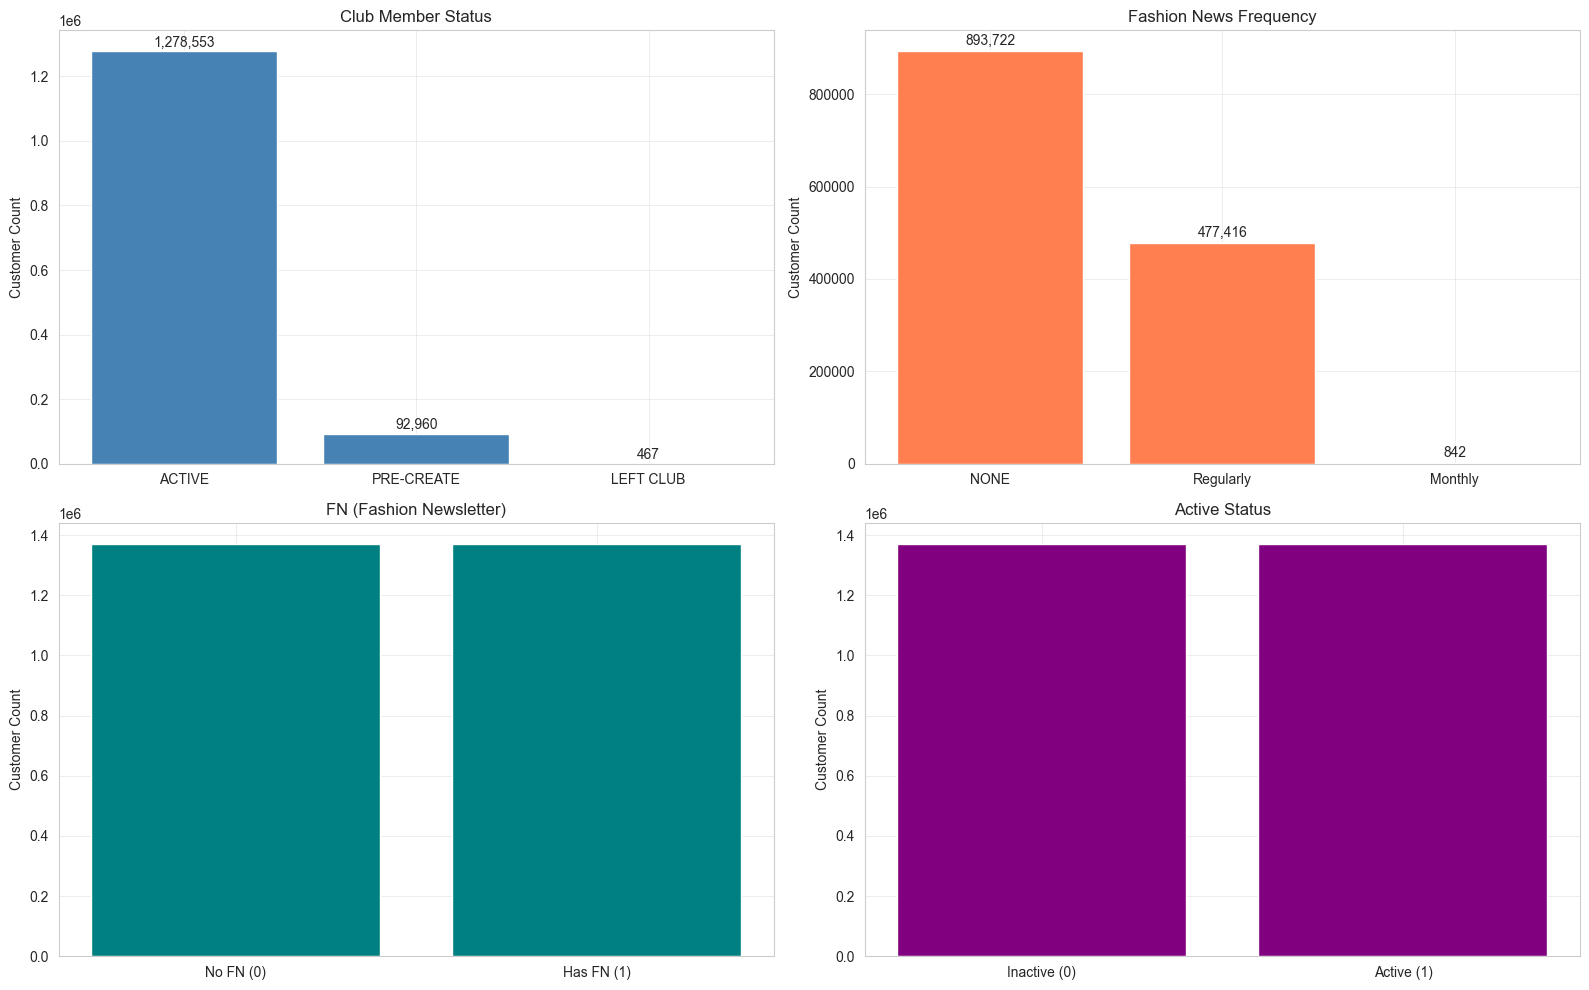

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

club_counts = customers['club_member_status'].value_counts()
axes[0,0].bar(club_counts.index, club_counts.values, color='steelblue')
axes[0,0].set_title('Club Member Status')
axes[0,0].set_ylabel('Customer Count')
for i, v in enumerate(club_counts.values):
    axes[0,0].text(i, v + len(customers)*0.01, f'{v:,}', ha='center')

news_counts = customers['fashion_news_frequency'].value_counts()
axes[0,1].bar(news_counts.index, news_counts.values, color='coral')
axes[0,1].set_title('Fashion News Frequency')
axes[0,1].set_ylabel('Customer Count')
for i, v in enumerate(news_counts.values):
    axes[0,1].text(i, v + len(customers)*0.01, f'{v:,}', ha='center')

fn_counts = customers['FN'].value_counts()
axes[1,0].bar(['No FN (0)', 'Has FN (1)'], fn_counts.values, color='teal')
axes[1,0].set_title('FN (Fashion Newsletter)')
axes[1,0].set_ylabel('Customer Count')

active_counts = customers['Active'].value_counts()
axes[1,1].bar(['Inactive (0)', 'Active (1)'], active_counts.values, color='purple')
axes[1,1].set_title('Active Status')
axes[1,1].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

## 9. Pivot Tables — Cross Analysis

Look at relationships between two variables at once.

**HINT — what to look for:**
- Which age group buys which product group? (any strong preference?)
- Are there empty cells in the pivot? (some age groups don't buy some categories)
- Price by channel — is online cheaper or more expensive?
- Any surprising patterns? (e.g., young people buying more accessories?)
- Could these cross-features improve your model?

C:\Users\MysticByte\AppData\Local\Temp\ipykernel_30008\3604328848.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot1 = pd.pivot_table(tx_with_age, values='price', index='age_group',


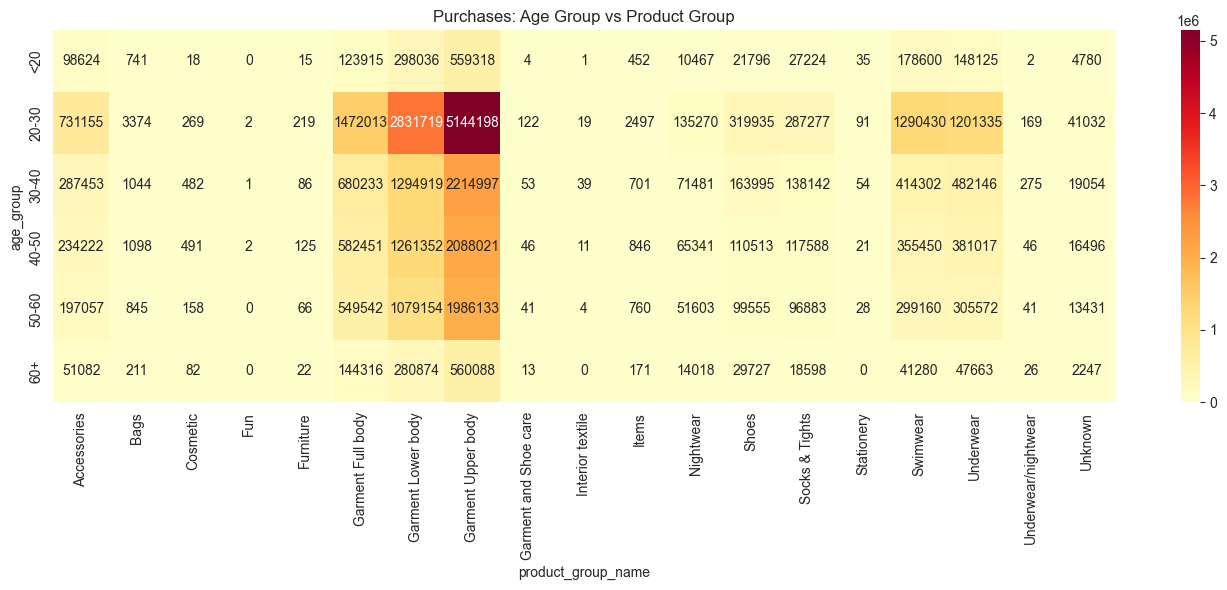

KeyError: 'product_group_name'

In [10]:
# Pivot 1: Age group vs Product group
tx_with_age = transactions.merge(customers[['customer_id', 'age']], on='customer_id', how='left')
tx_with_age = tx_with_age.merge(articles[['article_id', 'product_group_name']], on='article_id', how='left')
tx_with_age['age_group'] = pd.cut(tx_with_age['age'], bins=[0, 20, 30, 40, 50, 60, 100], 
                                    labels=['<20', '20-30', '30-40', '40-50', '50-60', '60+'])

pivot1 = pd.pivot_table(tx_with_age, values='price', index='age_group', 
                         columns='product_group_name', aggfunc='count', fill_value=0)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot1, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Purchases: Age Group vs Product Group')
plt.tight_layout()
plt.show()

# Pivot 2: Price by channel and product group
pivot2 = pd.pivot_table(tx_with_age.merge(articles[['article_id', 'product_group_name']], on='article_id', how='left'),
                         values='price', index='product_group_name', 
                         columns='sales_channel_id', aggfunc='mean')
pivot2.columns = ['Store (1)', 'Online (2)']

print('\nAverage Price by Product Group and Channel:')
print(pivot2.to_string())

## 10. Outlier Detection

Box plots showing outliers in key numeric columns.

**HINT — what to look for:**
- Dots above the whiskers = outliers (statistically unusual values)
- Price outliers: very expensive items — real luxury or errors?
- Age outliers: anyone with age 0 or 100+?
- Purchases-per-customer outliers: power buyers — keep or remove?
- Are outliers actually informative (real customer behavior) or noise (data errors)?

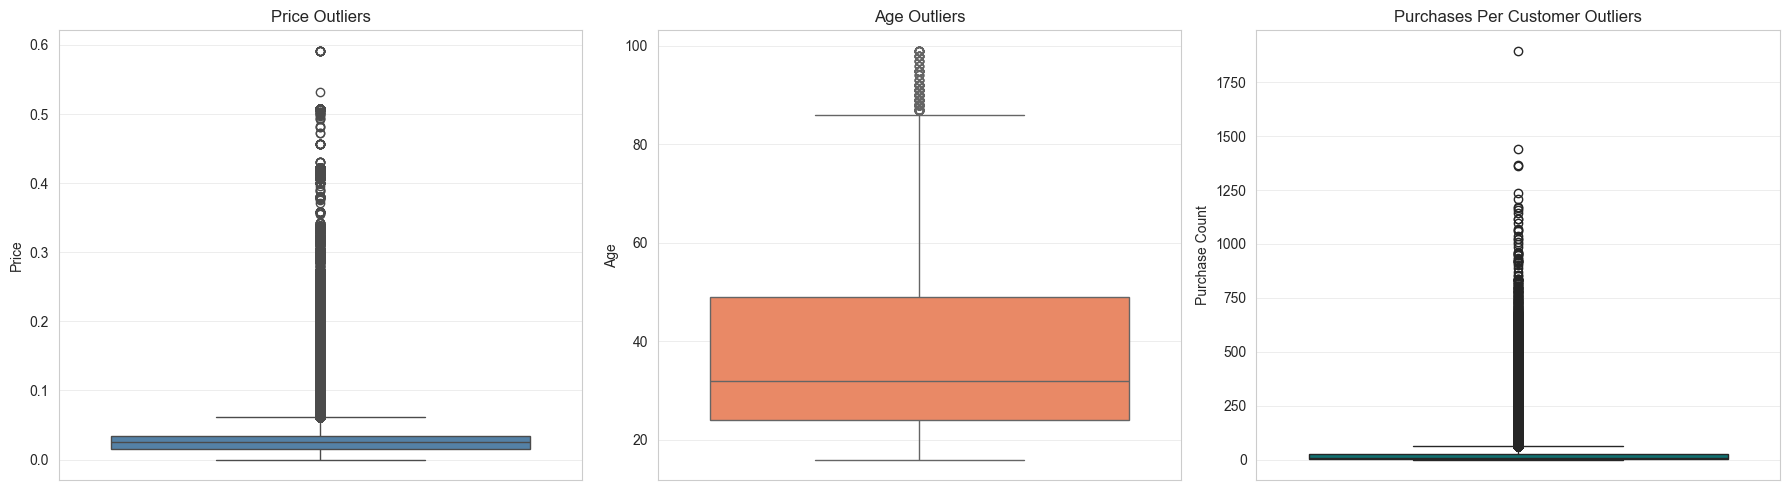

Price IQR: 0.0158 to 0.0339
Upper bound for outliers: 0.0610
Price outliers above bound: 1568312 (4.9%)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=transactions['price'], ax=axes[0], color='steelblue')
axes[0].set_title('Price Outliers')
axes[0].set_ylabel('Price')

sns.boxplot(y=customers['age'], ax=axes[1], color='coral')
axes[1].set_title('Age Outliers')
axes[1].set_ylabel('Age')

sns.boxplot(y=purchases_per_cust.values, ax=axes[2], color='teal')
axes[2].set_title('Purchases Per Customer Outliers')
axes[2].set_ylabel('Purchase Count')

plt.tight_layout()
plt.show()

# IQR method for price outliers
Q1 = transactions['price'].quantile(0.25)
Q3 = transactions['price'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
n_outliers = (transactions['price'] > upper_bound).sum()
print(f'Price IQR: {Q1:.4f} to {Q3:.4f}')
print(f'Upper bound for outliers: {upper_bound:.4f}')
print(f'Price outliers above bound: {n_outliers} ({n_outliers/len(transactions)*100:.1f}%)')

## 11. Repeat Purchases & Seasonality

Do customers buy the same item again? What day of week sells most?

**HINT — what to look for:**
- How often do customers buy the exact same article again? (very common in fashion?)
- Which day of week has most purchases? (weekend vs weekday)
- Which month has most sales? (seasonality for recommendations)
- Could day-of-week or month be a feature for the model?
- Could you add a "days_since_last_purchase" feature for each customer?

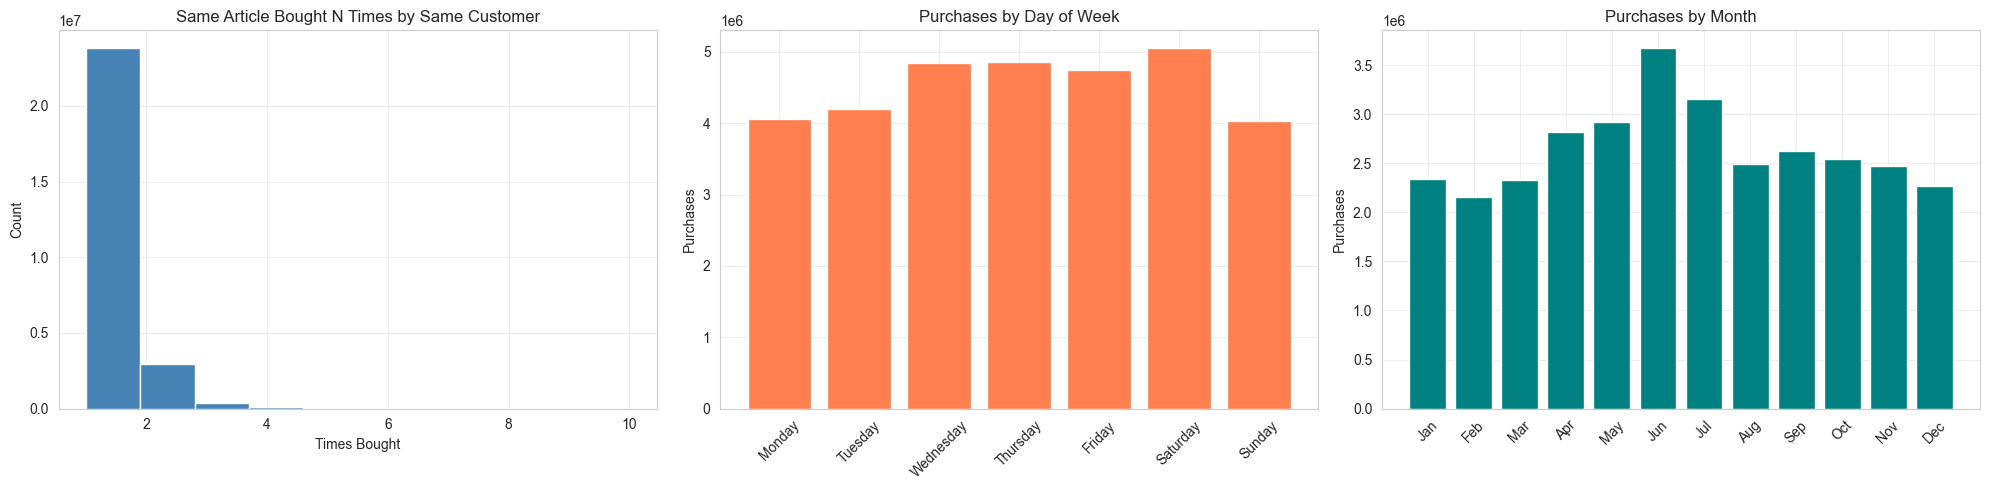

Customers who bought same article 3+ times: 577451
Most popular day: Saturday (5,049,500 purchases)


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Same article bought multiple times by same customer
repeat = transactions.groupby(['customer_id', 'article_id']).size()
axes[0].hist(repeat[repeat <= 10], bins=10, color='steelblue', edgecolor='white')
axes[0].set_title('Same Article Bought N Times by Same Customer')
axes[0].set_xlabel('Times Bought')
axes[0].set_ylabel('Count')

# Day of week
transactions['day_of_week'] = transactions['t_dat'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = transactions['day_of_week'].value_counts().reindex(day_order)
axes[1].bar(day_counts.index, day_counts.values, color='coral')
axes[1].set_title('Purchases by Day of Week')
axes[1].set_ylabel('Purchases')
axes[1].tick_params(axis='x', rotation=45)

# Month
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
transactions['month'] = transactions['t_dat'].dt.month
month_counts = transactions['month'].value_counts().sort_index()
axes[2].bar(month_names, [month_counts.get(i, 0) for i in range(1, 13)], color='teal')
axes[2].set_title('Purchases by Month')
axes[2].set_ylabel('Purchases')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f'Customers who bought same article 3+ times: {(repeat >= 3).sum()}')
print(f'Most popular day: {day_counts.idxmax()} ({day_counts.max():,} purchases)')

## 12. Ideas to Improve the Dataset

After exploring the visualizations, consider these questions:

**New features you could create:**
- Customer activity level (low/medium/high based on purchase count)
- Article popularity tier (top 100, mid, rare, never sold)
- Price bracket (cheap/mid/expensive based on the distribution you see)
- Age group (18-25, 26-35, 36-45, 46-55, 56+)
- Days since last purchase (recency feature)
- Day of week / month (seasonality feature)
- Channel preference (online-only, store-only, both)
- Repeat purchase rate per customer
- Category preference (customer's favourite product group)

**Data issues to check:**
- Price outliers — are they real luxury items or errors?
- Articles never bought — keep for cold-start or remove?
- Customers with 0 purchases — how to handle in recommendations?
- Does the median fill create a fake spike in age distribution?

**Things that could increase accuracy:**
- Adding customer purchase history as features
- Adding article popularity/trending features
- Adding time-based features (seasonality, day of week)
- Creating interaction features (age x product group, channel x price)